# Notebook 04 — Infrastructure Condition & Risk Proxy

**Purpose:** audit DS-3, explore infrastructure condition, compare baseline and tree models, and create an explicitly *proxy* risk score.

**Important limitations**
- DS-3 is a cross-sectional snapshot, not a longitudinal survival cohort.
- This notebook does **not** estimate survival probabilities, validated remaining useful life, or causal risk.
- `bridge_id` is an identifier, not a predictor. `structurally_deficient` is excluded from predictors because it may encode or closely reflect the condition label.
- Risk score is a transparent heuristic for exploration, not an actuarial or engineering decision tool.
- Dataset values and results should be interpreted as supplied-sample evidence until provenance is independently verified.


In [10]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

def find_project_root():
    # Works when launched from project root, ML/, or ML/notebooks/.
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "Data").is_dir() or (
            (candidate / "ML").is_dir() and (candidate / "requirements.txt").exists()
        ):
            return candidate
    # Common fallback when notebook is stored in ML/notebooks/.
    if here.name == "notebooks" and here.parent.name == "ML":
        return here.parent.parent
    return here

PROJECT_ROOT = Path(os.getenv("MATRISK_PROJECT_ROOT", find_project_root())).expanduser().resolve()
_output_override = os.getenv("MATRISK_OUTPUT_DIR")
OUTPUT_DIR = (
    Path(_output_override).expanduser().resolve()
    if _output_override
    else PROJECT_ROOT / "ML" / "outputs" / "notebook_04"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)

DATA_CANDIDATES = [
    Path(os.getenv("MATRISK_DATA_ROOT", "___NO_OVERRIDE___")),
    Path("Data"), Path("Data/raw"), Path("../Data"), Path("../Data/raw"),
    Path("../../Data"), Path("../../Data/raw"), Path("data/raw"), Path("data/external"),
    Path("."),
]
DATA_CANDIDATES = [p for p in DATA_CANDIDATES if str(p) != "___NO_OVERRIDE___"]

def find_dataset(filename):
    override = os.getenv("MATRISK_DATA_ROOT")
    candidates = ([Path(override)] if override else []) + DATA_CANDIDATES
    seen = set()
    for folder in candidates:
        folder = folder.expanduser()
        if str(folder) in seen:
            continue
        seen.add(str(folder))
        candidate = folder / filename
        if candidate.is_file():
            print(f"Found dataset: {candidate.resolve()}")
            return candidate
    raise FileNotFoundError(
        f"Could not find {filename}. Set MATRISK_DATA_ROOT to the folder containing the CSV, "
        "or place it in Data/ or Data/raw/. Checked: " + ", ".join(str(p.resolve()) for p in candidates)
    )

DATA_PATH = find_dataset("DS3_infrastructure_bridges_5000.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Project root: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk
Output directory: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_04
Found dataset: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS3_infrastructure_bridges_5000.csv
Shape: (5000, 24)


,bridge_id,bridge_type,material,year_built,age_years,design_life_years,location,corrosion_environment,corrosion_rate_mm_yr,condition_rating,...,yield_strength_MPa,paris_C,paris_m,original_thickness_mm,remaining_thickness_mm,fatigue_cycles_millions,replacement_cost_M,loan_outstanding_M,last_inspection_date,insurance_premium_K_yr
0,BR-00001,Pedestrian,Reinforced Concrete,1997,27,100,Urban Midwest,Moderate,0.0324,9,...,20,0.000000e+00,0.0,40.4,39.5,5.7,0.89,0.67,2022-06-26,15.9
1,BR-00002,Interstate,Reinforced Concrete,1953,71,100,Urban Midwest,Moderate,0.0320,7,...,20,0.000000e+00,0.0,44.1,41.9,202.7,0.99,0.45,2022-10-16,22.5
2,BR-00003,Local Road,FRP Composite,1989,35,100,Coastal California,Moderate,0.0265,9,...,500,0.000000e+00,0.0,38.0,37.1,150.0,1.52,0.63,2021-05-05,37.8
3,BR-00004,Pedestrian,Prestressed Concrete,1990,34,100,Coastal Florida,Severe,0.0638,7,...,28,0.000000e+00,0.0,66.9,64.8,10.3,0.21,0.12,2021-03-06,2.6
4,BR-00005,Highway,Steel (A588 Weathering),1975,49,75,Urban Midwest,Moderate,0.0199,8,...,345,5.200000e-12,2.8,23.6,22.7,606.6,0.14,0.08,2022-01-06,3.2


In [11]:
# 1. Schema and quality audit
required = ["bridge_id", "condition_rating", "age_years", "corrosion_rate_mm_yr"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "n_unique": df.nunique(dropna=True),
})
display(audit)

quality = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "duplicate_bridge_id_rows": int(df["bridge_id"].duplicated(keep=False).sum()),
    "missing_bridge_id": int(df["bridge_id"].isna().sum()),
    "condition_rating_outside_1_9": int((~df["condition_rating"].between(1, 9)).sum()),
    "age_negative": int((df["age_years"] < 0).sum()),
    "corrosion_rate_negative": int((df["corrosion_rate_mm_yr"] < 0).sum()),
    "remaining_thickness_gt_original": int((df["remaining_thickness_mm"] > df["original_thickness_mm"]).sum()),
    "structurally_deficient_values": sorted(df["structurally_deficient"].dropna().unique().tolist())
        if "structurally_deficient" in df else None,
}
print(json.dumps(quality, indent=2))
audit.to_csv(OUTPUT_DIR / "data_quality_audit.csv")
with open(OUTPUT_DIR / "data_quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(quality, f, indent=2)


,dtype,missing_count,missing_pct,n_unique
bridge_id,object,0,0.0,5000
bridge_type,object,0,0.0,5
material,object,0,0.0,11
year_built,int64,0,0.0,100
age_years,int64,0,0.0,100
design_life_years,int64,0,0.0,4
location,object,0,0.0,15
corrosion_environment,object,0,0.0,3
corrosion_rate_mm_yr,float64,0,0.0,1052
condition_rating,int64,0,0.0,10


{
  "rows": 5000,
  "columns": 24,
  "duplicate_bridge_id_rows": 0,
  "missing_bridge_id": 0,
  "condition_rating_outside_1_9": 5,
  "age_negative": 0,
  "corrosion_rate_negative": 0,
  "remaining_thickness_gt_original": 0,
  "structurally_deficient_values": [
    0,
    1
  ]
}


,count
condition_rating,
0,5
1,4
2,17
3,50
4,86
5,230
6,562
7,1148
8,1904


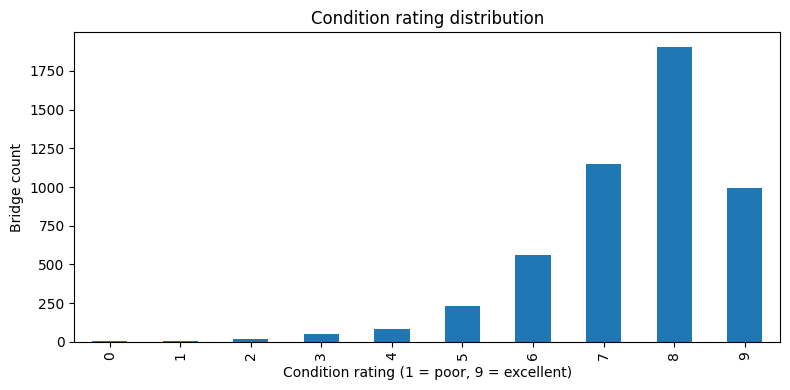

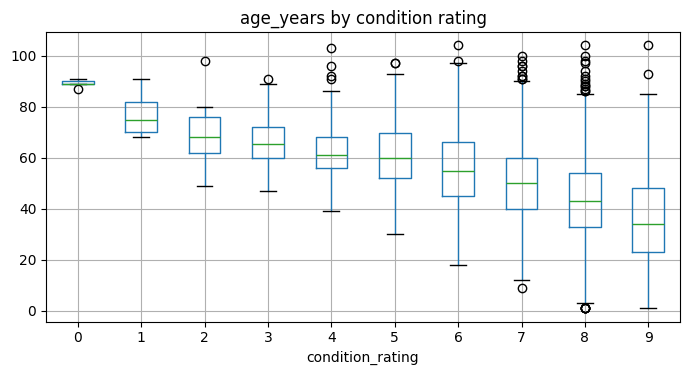

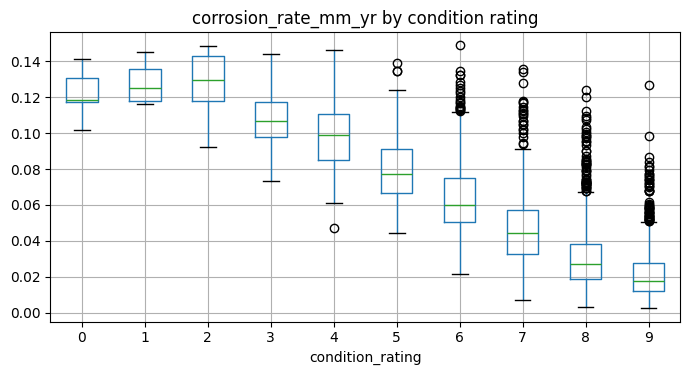

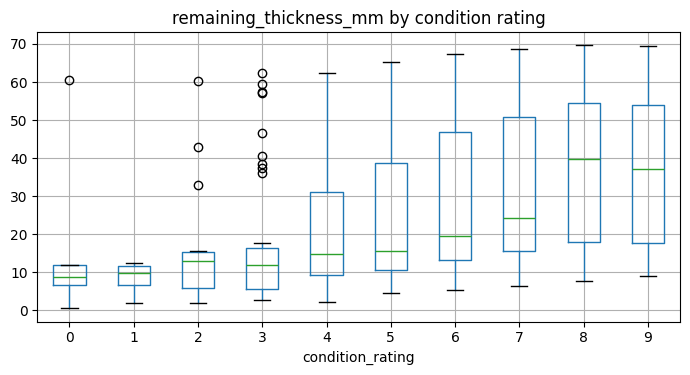

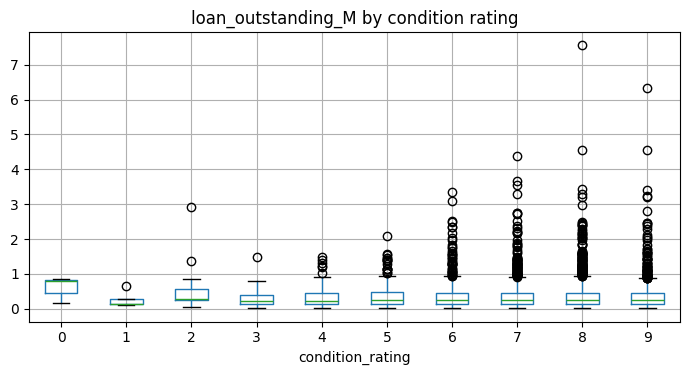

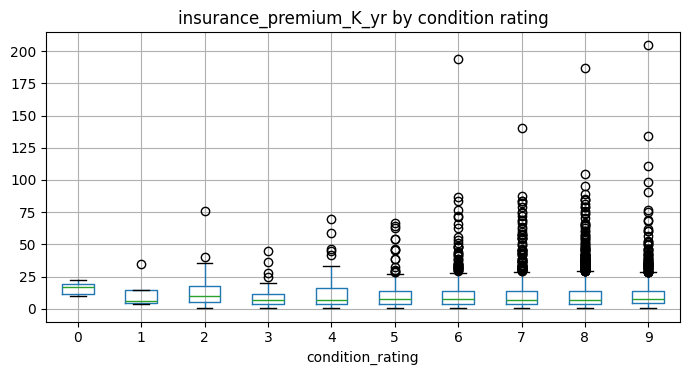

In [12]:
# 2. Exploratory analysis
display(df["condition_rating"].value_counts(dropna=False).sort_index().rename("count").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
df["condition_rating"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Condition rating distribution")
ax.set_xlabel("Condition rating (1 = poor, 9 = excellent)")
ax.set_ylabel("Bridge count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "condition_rating_distribution.png", dpi=140)
plt.show()

for col in ["age_years", "corrosion_rate_mm_yr", "remaining_thickness_mm", "loan_outstanding_M", "insurance_premium_K_yr"]:
    if col in df.columns:
        fig, ax = plt.subplots(figsize=(7, 4))
        df.boxplot(column=col, by="condition_rating", ax=ax)
        ax.set_title(f"{col} by condition rating")
        plt.suptitle("")
        plt.tight_layout()
        safe = "".join(ch if ch.isalnum() else "_" for ch in col)
        plt.savefig(OUTPUT_DIR / f"{safe}_by_condition.png", dpi=140)
        plt.show()


## 3. Model target and leakage controls

We treat `condition_rating` as an ordinal numeric target for a first regression benchmark and separately evaluate a classifier. This is a prediction exercise on the supplied snapshot, not proof of future-condition prediction.

Predictors exclude:
- `bridge_id`: identifier
- `condition_rating`: target
- `structurally_deficient`: potentially target-derived/closely coupled label
- `last_inspection_date`: not used as an absolute timestamp in this baseline
- `insurance_premium_K_yr`, `loan_outstanding_M`, `replacement_cost_M`: excluded from condition prediction to reduce target-adjacent financial leakage and keep the model focused on engineering attributes.

We also exclude `remaining_thickness_mm` from the first predictor set because it may be mathematically derived from original thickness, age and corrosion and could create shortcut learning. It remains available for descriptive EDA.


In [13]:
# 4. Prepare modeling table
target = "condition_rating"
excluded = {
    "bridge_id", target, "structurally_deficient", "last_inspection_date",
    "insurance_premium_K_yr", "loan_outstanding_M", "replacement_cost_M",
    "remaining_thickness_mm",
}
feature_cols = [c for c in df.columns if c not in excluded]
model_df = df.loc[df[target].notna() & df["bridge_id"].notna()].copy()
model_df = model_df[model_df[target].between(1, 9)].copy()

# IDs must be unique for an independent row-level split.
duplicate_ids = model_df["bridge_id"].duplicated(keep=False)
if duplicate_ids.any():
    raise ValueError(
        f"Found {int(duplicate_ids.sum())} rows with repeated bridge IDs. "
        "Resolve repeated IDs before using this split."
    )

X = model_df[feature_cols].copy()
y = model_df[target].astype(float).copy()

# Convert dates if any are among predictors; date field is excluded above.
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features),
])

# Stratify by rating class when feasible, preserving class representation.
class_counts = y.value_counts()
stratify_y = y if class_counts.min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=stratify_y
)
train_ids = set(model_df.loc[X_train.index, "bridge_id"])
test_ids = set(model_df.loc[X_test.index, "bridge_id"])
assert train_ids.isdisjoint(test_ids)

print(f"Features: {len(feature_cols)} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
print(f"Train: {len(X_train):,}; test: {len(X_test):,}")
print("Bridge ID overlap:", len(train_ids & test_ids))
print("Train rating distribution:")
display(y_train.value_counts().sort_index().to_frame("count"))


Features: 16 (12 numeric, 4 categorical)
Train: 3,996; test: 999
Bridge ID overlap: 0
Train rating distribution:


,count
condition_rating,
1.0,3
2.0,14
3.0,40
4.0,69
5.0,184
6.0,450
7.0,918
8.0,1523
9.0,795


In [14]:
# 5. Regression benchmark: predict numeric condition rating
regressors = {
    "DummyMedian": DummyRegressor(strategy="median"),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=180, min_samples_leaf=3, max_features=0.9,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}
reg_results = []
reg_fitted = {}

for name, estimator in regressors.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    reg_fitted[name] = pipe
    reg_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
    })

reg_metrics = pd.DataFrame(reg_results).sort_values("MAE").reset_index(drop=True)
display(reg_metrics)
reg_metrics.to_csv(OUTPUT_DIR / "condition_regression_metrics.csv", index=False)

best_reg_name = reg_metrics.iloc[0]["model"]
best_reg = reg_fitted[best_reg_name]
reg_pred = best_reg.predict(X_test)


,model,MAE,RMSE,R2
0,ExtraTrees,0.466348,0.578111,0.801548
1,DummyMedian,0.934935,1.404269,-0.170935


In [15]:
# 6. Classification benchmark: treat each rating as a class
# DummyClassifier provides a majority-class baseline.
classifiers = {
    "DummyMostFrequent": DummyClassifier(strategy="most_frequent"),
    "ExtraTreesClassifier": ExtraTreesClassifier(
        n_estimators=180, min_samples_leaf=3, max_features=0.9,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
}
class_results = []
class_fitted = {}

y_train_cls = y_train.astype(int)
y_test_cls = y_test.astype(int)

for name, estimator in classifiers.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train_cls)
    pred = pipe.predict(X_test).astype(int)
    class_fitted[name] = pipe
    class_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_cls, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_cls, pred),
        "macro_f1": f1_score(y_test_cls, pred, average="macro", zero_division=0),
    })

class_metrics = pd.DataFrame(class_results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(class_metrics)
class_metrics.to_csv(OUTPUT_DIR / "condition_classification_metrics.csv", index=False)

best_cls_name = class_metrics.iloc[0]["model"]
best_cls = class_fitted[best_cls_name]
cls_pred = best_cls.predict(X_test).astype(int)
print(classification_report(y_test_cls, cls_pred, zero_division=0))


,model,accuracy,balanced_accuracy,macro_f1
0,ExtraTreesClassifier,0.575576,0.474645,0.447011
1,DummyMostFrequent,0.381381,0.111111,0.061353


              precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.40      0.67      0.50         3
           3       0.23      0.30      0.26        10
           4       0.33      0.29      0.31        17
           5       0.61      0.61      0.61        46
           6       0.55      0.63      0.59       112
           7       0.55      0.55      0.55       230
           8       0.63      0.53      0.58       381
           9       0.57      0.68      0.62       199

    accuracy                           0.58       999
   macro avg       0.43      0.47      0.45       999
weighted avg       0.58      0.58      0.57       999



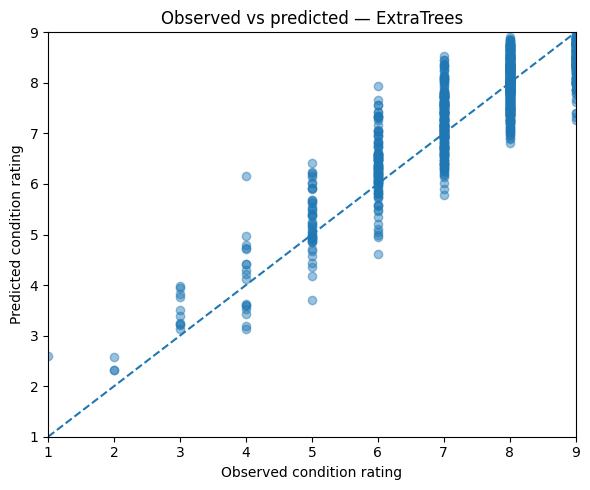

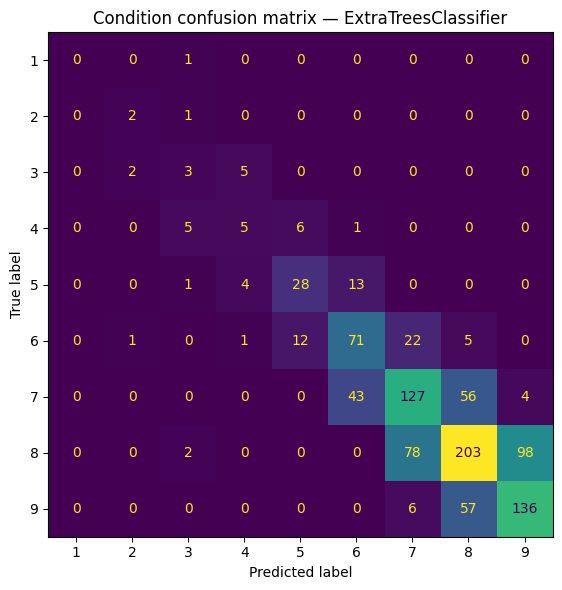

,bridge_id,observed_condition_rating,predicted_condition_rating,predicted_condition_class,absolute_error
0,BR-01684,7.0,8.043796,8,1.043796
1,BR-00816,8.0,8.798704,9,0.798704
2,BR-00877,9.0,7.674676,7,1.325324
3,BR-03612,5.0,5.615833,6,0.615833
4,BR-04431,5.0,5.384630,5,0.384630


In [16]:
# 7. Diagnostics and saved predictions
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, reg_pred, alpha=0.45)
ax.plot([1, 9], [1, 9], linestyle="--")
ax.set_xlim(1, 9); ax.set_ylim(1, 9)
ax.set_xlabel("Observed condition rating")
ax.set_ylabel("Predicted condition rating")
ax.set_title(f"Observed vs predicted — {best_reg_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "condition_regression_observed_vs_predicted.png", dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, cls_pred, labels=list(range(1, 10)),
    normalize=None, ax=ax, colorbar=False
)
ax.set_title(f"Condition confusion matrix — {best_cls_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "condition_classification_confusion_matrix.png", dpi=140)
plt.show()

predictions = pd.DataFrame({
    "bridge_id": model_df.loc[X_test.index, "bridge_id"].values,
    "observed_condition_rating": y_test.values,
    "predicted_condition_rating": reg_pred,
    "predicted_condition_class": cls_pred,
    "absolute_error": np.abs(y_test.values - reg_pred),
})
predictions.to_csv(OUTPUT_DIR / "heldout_condition_predictions.csv", index=False)
display(predictions.head())


## 8. Transparent risk proxy (not a probability)

For dashboard prototyping only, calculate a 0–100 heuristic using age relative to design life, corrosion rate relative to the sample's 95th percentile, and inverse condition rating. Weights are explicit and adjustable. This is **not** calibrated to observed failure rates and must not be called probability of failure or remaining useful life.


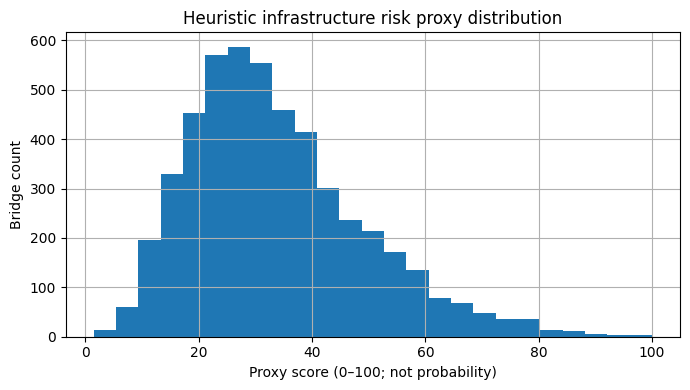

,risk_proxy_0_100,condition_rating,age_years,corrosion_rate_mm_yr
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,33.685538,7.453600,46.568400,0.040924
std,15.442191,1.320832,17.910083,0.026408
min,1.427638,0.000000,1.000000,0.002300
25%,22.525518,7.000000,34.000000,0.021300
50%,31.043237,8.000000,46.000000,0.034700
75%,42.501312,8.000000,59.000000,0.054825
max,100.000000,9.000000,104.000000,0.148900


In [17]:
# Heuristic risk proxy on the full descriptive dataset; not a trained model.
risk = df.copy()
design_life = pd.to_numeric(risk["design_life_years"], errors="coerce").replace(0, np.nan)
age_ratio = (pd.to_numeric(risk["age_years"], errors="coerce") / design_life).clip(0, 1.5) / 1.5
corr = pd.to_numeric(risk["corrosion_rate_mm_yr"], errors="coerce").clip(lower=0)
corr_scale = corr.quantile(0.95)
corr_norm = (corr / corr_scale).clip(0, 1) if pd.notna(corr_scale) and corr_scale > 0 else pd.Series(0.0, index=risk.index)
condition_risk = (9 - pd.to_numeric(risk["condition_rating"], errors="coerce")).clip(0, 8) / 8

risk["risk_proxy_0_100"] = 100 * (
    0.30 * age_ratio.fillna(0) +
    0.30 * corr_norm.fillna(0) +
    0.40 * condition_risk.fillna(condition_risk.median())
)
risk[["bridge_id", "condition_rating", "age_years", "corrosion_rate_mm_yr", "risk_proxy_0_100"]].to_csv(
    OUTPUT_DIR / "infrastructure_risk_proxy.csv", index=False
)

fig, ax = plt.subplots(figsize=(7, 4))
risk["risk_proxy_0_100"].hist(bins=25, ax=ax)
ax.set_title("Heuristic infrastructure risk proxy distribution")
ax.set_xlabel("Proxy score (0–100; not probability)")
ax.set_ylabel("Bridge count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "risk_proxy_distribution.png", dpi=140)
plt.show()
display(risk[["risk_proxy_0_100", "condition_rating", "age_years", "corrosion_rate_mm_yr"]].describe())


In [18]:
# 9. Final summary and reproducibility assertions
assert train_ids.isdisjoint(test_ids)
assert len(predictions) == len(X_test)
assert set(predictions["bridge_id"]).issubset(set(df["bridge_id"]))

summary = {
    "dataset_path": str(DATA_PATH.resolve()),
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_test_bridge_id_overlap": int(len(train_ids & test_ids)),
    "target": target,
    "predictor_columns": feature_cols,
    "excluded_columns": sorted(excluded),
    "best_regression_model_by_test_MAE_for_diagnostic_only": best_reg_name,
    "regression_metrics": reg_metrics.to_dict(orient="records"),
    "best_classifier_by_test_macro_f1_for_diagnostic_only": best_cls_name,
    "classification_metrics": class_metrics.to_dict(orient="records"),
    "risk_proxy": {
        "name": "heuristic_risk_proxy_0_100",
        "weights": {"age_vs_design_life": 0.30, "corrosion_relative_to_p95": 0.30, "condition_rating": 0.40},
        "warning": "Not calibrated; not a probability of failure, survival estimate, or RUL prediction."
    },
    "limitations": [
        "Cross-sectional data; no observed event times/censoring cohort for survival analysis.",
        "Metrics describe only this supplied sample and split.",
        "Dataset provenance and label-generation process are not independently verified.",
        "Financial variables were excluded from condition predictors to reduce target-adjacent leakage.",
    ],
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("Outputs saved to:", OUTPUT_DIR.resolve())


{
  "dataset_path": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS3_infrastructure_bridges_5000.csv",
  "rows": 5000,
  "columns": 24,
  "train_rows": 3996,
  "test_rows": 999,
  "train_test_bridge_id_overlap": 0,
  "target": "condition_rating",
  "predictor_columns": [
    "bridge_type",
    "material",
    "year_built",
    "age_years",
    "design_life_years",
    "location",
    "corrosion_environment",
    "corrosion_rate_mm_yr",
    "adt",
    "deck_area_sqft",
    "tensile_strength_MPa",
    "yield_strength_MPa",
    "paris_C",
    "paris_m",
    "original_thickness_mm",
    "fatigue_cycles_millions"
  ],
  "excluded_columns": [
    "bridge_id",
    "condition_rating",
    "insurance_premium_K_yr",
    "last_inspection_date",
    "loan_outstanding_M",
    "remaining_thickness_mm",
    "replacement_cost_M",
    "structurally_deficient"
  ],
  "best_regression_model_by_test_MAE_for_diagnostic_only": "ExtraTrees",
  "regression_metrics": [
    {
      "model":